<a href="https://colab.research.google.com/github/BarGinger/Deep_Learning_MEG/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning - Assigment 2

### Group Number: 22

### Teammates:
1. **Mahshid Jafar Tajrishi**
2. **Bar Melinarskiy**
3. **Cis van Aken**
4. **Simon van Klompenburg**

## Imports entire notebook

In [1]:
# Helper function to check if the code is running in Google Colab
def is_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

# Usage
if is_colab():
    print("Running in Google Colab")
else:
    print("Not running in Google Colab")


# Importing libraries
import pandas as pd
import numpy as np
import Models
import utils as utils
import torch
import matplotlib.pyplot as plt
import os
import random
import datetime
import importlib
importlib.reload(utils)
importlib.reload(Models)

Not running in Google Colab
Generated 0 mesh combos for 248 channels: []
Generated 0 mesh combos for 248 channels: []


<module 'Models' (namespace) from ['c:\\Users\\bar24\\OneDrive - Universiteit Utrecht\\Documents\\School\\UU Data Sceince MSc\\1st Year\\Period 4\\Deep learning (INFOMDLR)\\Assignments\\Deep_Learning_MEG\\Models']>

## Global Definitions

In [2]:
# Path to the zip file
data_dir = "./Data"
google_drive_folder = "/content/drive/MyDrive/UU"
zip_path = f"{data_dir}/Final Project data.zip"
output_dir = "./Output"
model_dir = "./Models"

# check if outpiut directory exists
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# check if model directory exists
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Set the device to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

debug_mode = False

# Set pandas display options to show all columns
pd.set_option('display.max_columns', None)

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# model and data related parameters
scaler_type = utils.NormalizationType.Z_SCORE_LOCAL  # or MINMAX_LOCAL, Z_SCORE_TIMEWISE
which_dataset = "cross"  # or "cross"
downsample = True  # or False
downsample_rate = 0  
if downsample:
    downsample_rate = 7

### Check if we have cude

In [3]:
# Check if CUDA is available
print(torch.__version__)
print(torch.version.cuda)  # Should match CUDA 12.5
print(torch.backends.cudnn.version())  # Should return a version, not None
print(torch.cuda.is_available())  # Should return True

2.5.1
None
90100
True


### Load the datasets

In [4]:
train_data, train_df, test_data, test_df = utils.load_dataset(
    which_dataset=which_dataset,
    data_dir=data_dir,
    scaler_type=scaler_type,
    downsample_rate=downsample_rate
)

Loading cross dataset...
Loading cached: Data\Normalized\z_score_local\cross_train_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test1_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test2_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test3_scaled.pt
Data for dataset cross was loaded successfully


### Definitions for training and logging

In [5]:
# Check if the data is loaded correctly
print("train task types counts:")
print(np.bincount(train_df['task_type'].astype('category').cat.codes))
print("test task types counts:")
print(np.bincount(test_df['task_type'].astype('category').cat.codes))


timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
# Set this once at the top of your notebook/cell
MODEL_NAME = utils.ModelClass.__name__ # "MEGClassifier"
print(f"Using model class: {MODEL_NAME}")
model_name = f"{MODEL_NAME}_{which_dataset}"
model_pth_path = f"{model_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.pth"
model_csv_path = f"{output_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.csv"
model_json_path = f"{model_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.json"
best_model = None

# create folders if they do not exist
if not os.path.exists(f"{model_dir}/{which_dataset}"):
    os.makedirs(f"{model_dir}/{which_dataset}")


if not os.path.exists(f"{output_dir}/{which_dataset}"):
    os.makedirs(f"{output_dir}/{which_dataset}")

train task types counts:
[16 16 16 16]
test task types counts:
[12 12 12 12]
Using model class: MultiviewAttention


### load the cross dataset best parameters to check with more data (using the Intra train dataset)


In [6]:
import json

# test_metrics_MultiviewAttention_cross_20250529_213144 cross_20250529_213144 
json_path = f"{model_dir}/Cross/best_model_MultiviewAttention_cross_20250529_213144.json" # intra_20250601_225149.json
best_params = None


with open(json_path) as f:
    best_params = json.load(f)

best_params["number_channels"] = train_data.shape[1]
best_params["depth"] = 1  # <-- set to 1 for new model
# best_params["conv1_filters"] = 64  # <-- set to 1 for new model
# best_params["conv2_filters"] = 128  # <-- set to 1 for new model
best_params["number_classes"] = len(np.unique(train_df['task_type']))
best_params["num_classes"] = len(np.unique(train_df['task_type']))
# Recompute split_size if missing
if "split_size" not in best_params:
    T = train_data.shape[2]
    best_params["split_size"] = T // best_params["window_size"]

# # Always set mesh_rows and mesh_columns for new model
best_params["mesh_rows"] = 8
best_params["mesh_columns"] = 31

# best_params["window_size"] = 30
# best_params["batch_size"] = 8
best_params["dropout_rate"] = 0.3
best_params["number_of_heads"] = 4
# best_params["lstm1_layers"] = 4
# best_params["lstm2_layers"] = 4
# best_params["conv1_activation"] = "relu"
# best_params["conv2_activation"] = "relu"
# best_params["conv3_activation"] = "relu"
# best_params["dense_activation"] = "relu"
# best_params["dense3_activation"] = "relu"
# best_params["optimizer"] = "adamw"
# best_params["conv1_kernel_shape"] = [3, 3]
# best_params["conv2_kernel_shape"] = [1, 3]

print("Best parameters loaded:", json.dumps(best_params, indent=4))


Best parameters loaded: {
    "window_size": 4,
    "mesh_rows_index": 1,
    "conv1_filters": 16,
    "conv2_filters": 128,
    "conv3_filters": 256,
    "conv1_kernel_shape": [
        5,
        5
    ],
    "conv2_kernel_shape": [
        7,
        7
    ],
    "conv3_kernel_shape": [
        3,
        3
    ],
    "padding1": 1,
    "padding2": 1,
    "padding3": 2,
    "conv1_activation": "elu",
    "conv2_activation": "leaky_relu",
    "conv3_activation": "relu",
    "dense_nodes": 256,
    "dense_activation": "leaky_relu",
    "depth": 1,
    "lstm1_cells": 32,
    "lstm2_cells": 256,
    "dense3_nodes": 32,
    "dense3_activation": "gelu",
    "learning_rate": 0.004163758322977153,
    "batch_size": 8,
    "dropout_rate": 0.3,
    "optimizer": "rmsprop",
    "weight_decay": 0.00020390156741294013,
    "label_smoothing": 0.0,
    "transformer_nhead": 2,
    "transformer_layers": 1,
    "number_channels": 248,
    "number_classes": 4,
    "split_size": 989,
    "mesh_rows": 8,

In [7]:
# Initialize the model with the best parameters
best_model = utils.ModelClass(**{k: v for k, v in best_params.items() if k in utils.ModelClass.__init__.__code__.co_varnames}).to(device)

# Dataloader
train_loader = utils.get_multiview_dataloader(
    train_data, train_df,
    batch_size=best_params["batch_size"],
    window_size=best_params["window_size"],
    mesh_rows=best_params["mesh_rows"],
    mesh_columns=best_params["mesh_columns"],
    depth=best_params["depth"],
    shuffle=True,
    augment=True
)

c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\torch\nn\modules\rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.3 and num_layers=1
  warnings.warn(


Full Training:  44%|████▍     | 22/50 [01:57<02:29,  5.32s/epoch, F1=0.984, accuracy=0.984, loss=0.0711]


Early stopping triggered after 23 epochs (train_accuracy > 0.95).
Train metrics saved to ./Output/cross/train_metrics_MultiviewAttention_cross_20250609_151119.csv
Per-patient, per-task train accuracy saved to ./Output/cross/train_per_patient_task_accuracy_MultiviewAttention_cross_20250609_151119.csv
Total Train Accuracy: 0.9844


C:\Users\bar24\AppData\Local\Temp\ipykernel_11256\1571389866.py:108: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda df: (df['y_true'] == df['y_pred']).mean())


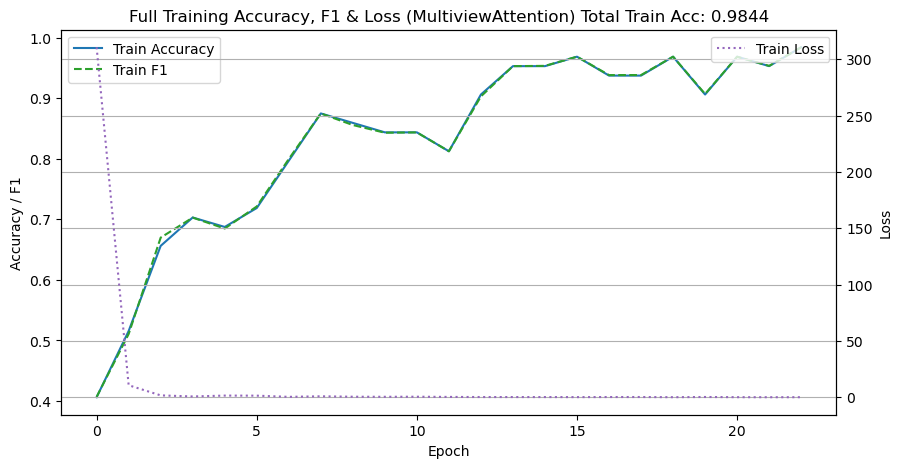

In [18]:
from tqdm import tqdm

# Training hyperparameters
epochs = 50
verbose = True
min_delta = 1e-4      # Minimum improvement to reset patience
patience = 15         # Early stopping patience

train_accs, train_f1s, train_losses = [], [], []

optimizer_name = best_params.get("optimizer", "adamw")
weight_decay = best_params.get("weight_decay", 1e-4)
learning_rate = best_params.get("learning_rate", 0.001)
label_smoothing = best_params.get("label_smoothing", 0.15)

optimizer, scheduler, criterion = utils.get_training_parts(
    best_model, lr=learning_rate, max_epochs=epochs,
    optimizer_name=optimizer_name,
    weight_decay=weight_decay,
    label_smoothing=label_smoothing
)

best_train_loss = float('inf')
epochs_without_improvement = 0

epochs_pbar = tqdm(range(epochs), desc="Full Training", unit="epoch")
for epoch in epochs_pbar:
    train_preds, train_targets, train_loss = utils.single_train_epoch(
        model=best_model, 
        train_loader=train_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=device
    )
    train_metrics = best_model.evaluate(y_true=train_targets, y_pred=train_preds)
    train_accs.append(train_metrics["overall_accuracy"])
    train_f1s.append(train_metrics["overall_F1"])
    train_losses.append(train_loss)
    scheduler.step()

    # Update progress bar
    epochs_pbar.set_postfix(
        accuracy=train_metrics["overall_accuracy"],
        F1=train_metrics["overall_F1"],
        loss=train_loss
    )

    # Early stopping logic (on training loss)
    if train_loss < best_train_loss - min_delta:
        best_train_loss = train_loss
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
    if epochs_without_improvement >= patience:
        print(f"Early stopping triggered after {epoch+1} epochs (no train_loss improvement).")
        break

    if train_metrics["overall_accuracy"] > 0.98:
        print(f"Early stopping triggered after {epoch+1} epochs (train_accuracy > 0.95).")
        break


# Get predictions and targets for the whole train set
all_train_preds, all_train_targets = [], []
best_model.eval()
with torch.no_grad():
    for batch in train_loader:
        x_cnn_list, x_lstm_list, y = batch
        x_cnn_list = [x.to(device) for x in x_cnn_list]
        x_lstm_list = [x.to(device) for x in x_lstm_list]
        outputs = best_model(x_cnn_list, x_lstm_list)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_train_preds.extend(preds)
        all_train_targets.extend(y.cpu().numpy())

# Evaluate metrics
train_metrics = best_model.evaluate(np.array(all_train_preds), np.array(all_train_targets))

# Save to CSV
train_metrics_df = pd.DataFrame([train_metrics])
train_metrics_csv_path = f"{output_dir}/{which_dataset}/train_metrics_{model_name}_{timestamp}.csv"
train_metrics_df.to_csv(train_metrics_csv_path, index=False)
print(f"Train metrics saved to {train_metrics_csv_path}")

# --- Per-patient, per-task accuracy on train set ---
train_patient_ids = train_df['patient_id'].values
train_task_types = train_df['task_type_cat'].values

# Expand patient_ids and task_types to match windowed samples if using sliding windows
if len(all_train_preds) != len(train_patient_ids):
    # If you used sliding windows or data augmentation, you may need to reconstruct the mapping
    # For MultiviewDataset, usually each sample corresponds to one patient/trial
    # If you used windows, you may need to repeat patient_ids accordingly
    # Here we assume 1:1 mapping (adjust if needed)
    pass

train_results_df = pd.DataFrame({
    "patient_id": train_patient_ids,
    "task_type": train_task_types,
    "y_true": all_train_targets,
    "y_pred": all_train_preds
})

# Compute per-patient, per-task accuracy
per_patient_task_acc = (
    train_results_df
    .groupby(['patient_id', 'task_type'])
    .apply(lambda df: (df['y_true'] == df['y_pred']).mean())
    .unstack(fill_value=np.nan)
)

per_patient_task_acc_csv = f"{output_dir}/{which_dataset}/train_per_patient_task_accuracy_{model_name}_{timestamp}.csv"
per_patient_task_acc.to_csv(per_patient_task_acc_csv)
print(f"Per-patient, per-task train accuracy saved to {per_patient_task_acc_csv}")

total_train_acc = train_accs[-1] if train_accs else 0.0
print(f"Total Train Accuracy: {total_train_acc:.4f}")

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(train_accs, label="Train Accuracy", color='tab:blue')
ax1.plot(train_f1s, label="Train F1", linestyle="--", color='tab:green')
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy / F1")
ax1.tick_params(axis='y')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(train_losses, label="Train Loss", linestyle=":", color='tab:purple')
ax2.set_ylabel("Loss")
ax2.tick_params(axis='y')
ax2.legend(loc='upper right')

plt.title(f"Full Training Accuracy, F1 & Loss ({utils.ModelClass.__name__}) Total Train Acc: {total_train_acc:.4f}")
plt.grid(True)
path = f"{output_dir}/{which_dataset}/full_train_{utils.ModelClass.__name__}_{timestamp}.png"
plt.savefig(path, bbox_inches='tight')
plt.show()

#### Saving the final model

In [9]:
# Create the model with the best hyperparameters
torch.save(best_model.state_dict(), model_pth_path)
print(f"Best model saved to {model_pth_path}")

# Save the best hyperparameters to a JSON file
with open(model_json_path, "w") as json_file:
    json.dump(best_params, json_file, indent=4)
print(f"Best hyperparameters saved to {model_json_path}")

Best model saved to ./Models/cross/best_model_MultiviewAttention_cross_20250609_151119.pth
Best hyperparameters saved to ./Models/cross/best_model_MultiviewAttention_cross_20250609_151119.json


In [10]:
# Get a real batch from your train_loader
real_batch = next(iter(train_loader))
x_cnn_list, x_lstm_list, y = real_batch

# Move all tensors to the correct device
x_cnn_list = [x.to(device) for x in x_cnn_list]
x_lstm_list = [x.to(device) for x in x_lstm_list]

# Flatten for ONNX input
real_input = (*x_cnn_list, *x_lstm_list)
input_names = [f"x_cnn_{i}" for i in range(len(x_cnn_list))] + [f"x_lstm_{i}" for i in range(len(x_lstm_list))]

class ONNXWrapper(torch.nn.Module):
    def __init__(self, model, window_size):
        super().__init__()
        self.model = model
        self.window_size = window_size

    def forward(self, *inputs):
        x_cnn_list = list(inputs[:self.window_size])
        x_lstm_list = list(inputs[self.window_size:])
        return self.model(x_cnn_list, x_lstm_list)

onnx_model = ONNXWrapper(best_model, len(x_cnn_list)).to(device)
torch.onnx.export(
    onnx_model,
    real_input,
    f"{model_dir}/multiview_attention.onnx",
    input_names=input_names,
    output_names=["output"],
    opset_version=17
)
print("✅ Exported model to ONNX using real batch input.")

c:\Users\bar24\OneDrive - Universiteit Utrecht\Documents\School\UU Data Sceince MSc\1st Year\Period 4\Deep learning (INFOMDLR)\Assignments\Deep_Learning_MEG\Model.py:145: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if (self.rel_height is None) or (self.rel_height.shape[0] != 2*H-1):
c:\Users\bar24\OneDrive - Universiteit Utrecht\Documents\School\UU Data Sceince MSc\1st Year\Period 4\Deep learning (INFOMDLR)\Assignments\Deep_Learning_MEG\Model.py:150: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if (self.rel_width is None) or (self.rel_width.shape[0]

✅ Exported model to ONNX using real batch input.


In [11]:
from Model import print_model_summary

print_model_summary(best_model, input_shapes=(len(x_cnn_list), x_cnn_list[0].shape[1], x_cnn_list[0].shape[2]), device=device)

torchsummary failed: Failed to run torchsummary. See above stack traces for more details. Executed layers up to: []
Model architecture:
 MultiviewAttention(
  (act1): ELU(alpha=1.0)
  (act2): ReLU()
  (act3): ReLU()
  (act_dense): ReLU()
  (act_dense3): GELU(approximate='none')
  (cnn_branches): ModuleList(
    (0-3): 4 x Sequential(
      (0): AugmentedConv2D(
        (conv): Conv2d(1, 8, kernel_size=(5, 5), stride=(1, 1), padding=same)
        (attn): SelfAttention2D(
          (qkv_conv): Conv2d(1, 24, kernel_size=(1, 1), stride=(1, 1))
          (output_conv): Conv2d(8, 8, kernel_size=(1, 1), stride=(1, 1))
        )
      )
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ELU(alpha=1.0)
      (3): Dropout(p=0.3, inplace=False)
      (4): Conv2d(16, 128, kernel_size=(7, 7), stride=(1, 1), padding=(1, 1))
      (5): ReLU()
      (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(2, 2))
      (7): ReLU()
      (8): F

### Evulate model and save logs

In [19]:
test_csv_path = f"{output_dir}/{which_dataset}/test_metrics_{model_name}_{timestamp}.csv"

test_metrics, df_test_result = utils.evaluate_model_on_testset(
    best_model, test_data, test_df, device,
    batch_size=best_params.get("batch_size", 2),
    input_time_length=best_params.get("input_time_length", 256),
    stride=best_params.get("stride", 256),
    path=test_csv_path
)

print("Test metrics:", test_metrics, '\n')

Test metrics: {'overall_accuracy': 0.6666666666666666, 'overall_F1': 0.6648366013071896, 'overall_recall': 0.6666666666666666, 'overall_precision': 0.7307692307692308, 'resting_accuracy': 1.0, 'resting_F1': 1.0, 'resting_recall': 1.0, 'resting_precision': 1.0, 'math_accuracy': 0.6666666666666666, 'math_F1': 0.26666666666666666, 'math_recall': 0.2222222222222222, 'math_precision': 0.3333333333333333, 'memory_accuracy': 0.5833333333333334, 'memory_F1': 0.3684210526315789, 'memory_recall': 0.2916666666666667, 'memory_precision': 0.5, 'motor_accuracy': 0.4166666666666667, 'motor_F1': 0.19607843137254902, 'motor_recall': 0.1388888888888889, 'motor_precision': 0.3333333333333333} 



Generated 0 mesh combos for 248 channels: []


c:\Users\bar24\OneDrive - Universiteit Utrecht\Documents\School\UU Data Sceince MSc\1st Year\Period 4\Deep learning (INFOMDLR)\Assignments\Deep_Learning_MEG\utils.py:1230: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16, loc='upper left', bbox_to_anchor=(1.05, 1.0))


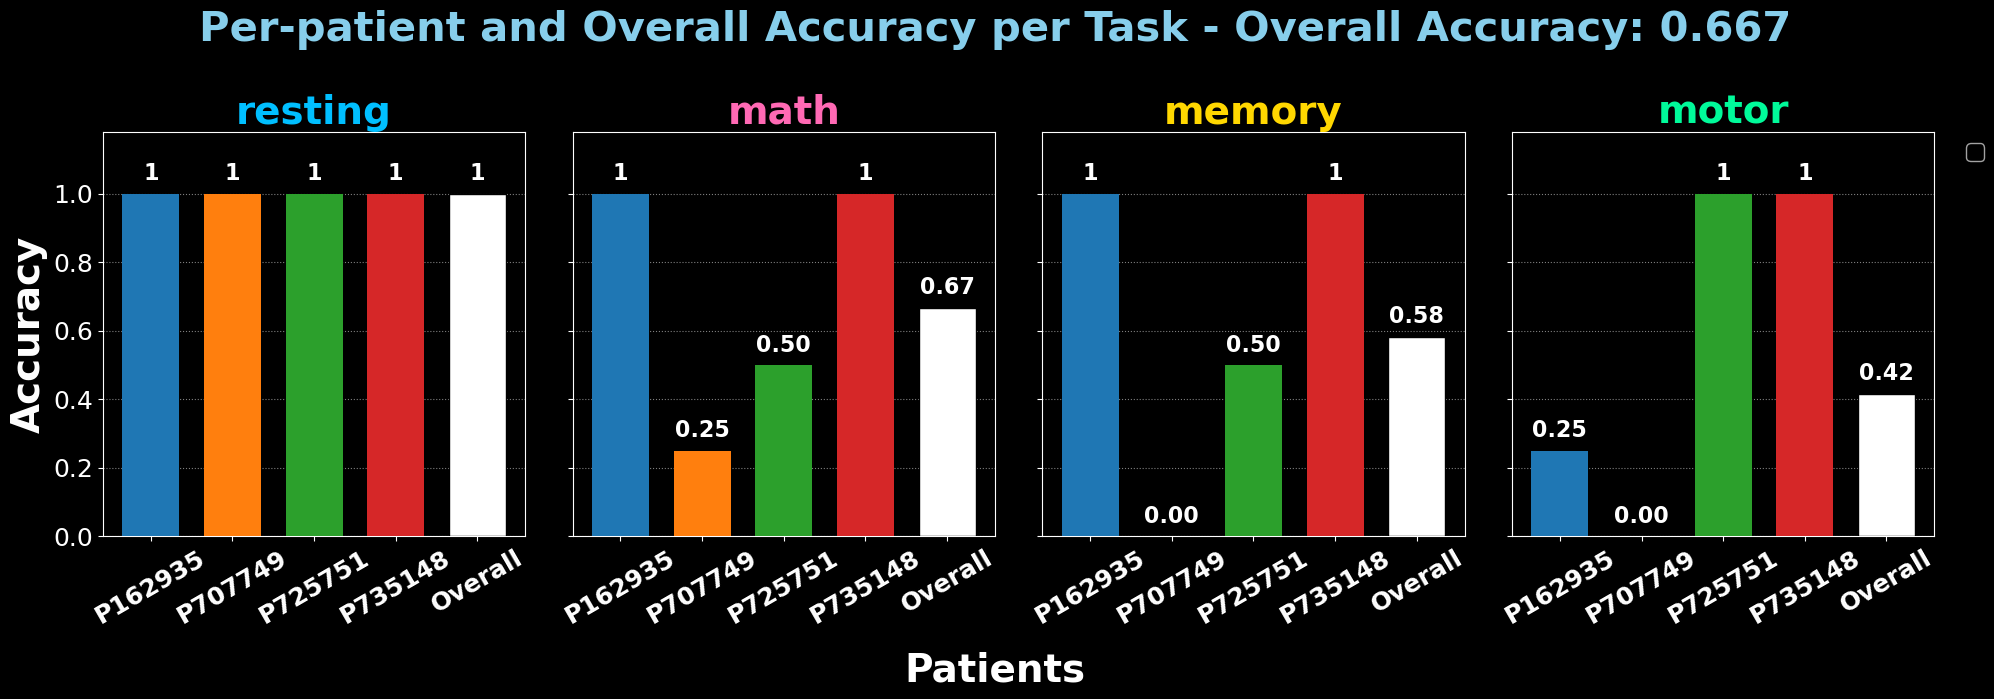

In [20]:
import importlib
importlib.reload(utils)

fig, axs, path, per_patient_acc, overall_acc_per_task = utils.plot_per_patient_accuracy_bars(
    df_test_result,
    output_dir,
    which_dataset,
    model_name,
    timestamp,
    task_names=["resting", "math", "memory", "motor"]
)

Generated 0 mesh combos for 248 channels: []


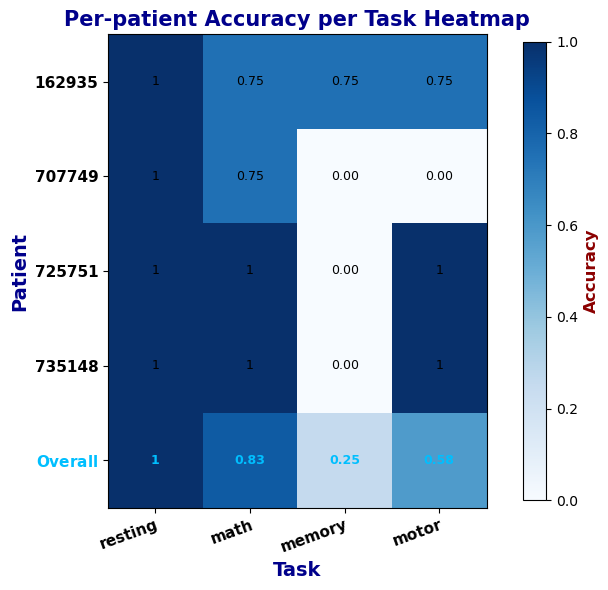

(<Figure size 1000x600 with 2 Axes>,
 <Axes: title={'center': 'Per-patient Accuracy per Task Heatmap'}, xlabel='Task', ylabel='Patient'>,
 './Output/cross/per_patient_accuracy_heatmap_MultiviewAttention_cross_20250609_151119.png')

In [14]:
import importlib
importlib.reload(utils)

utils.plot_per_patient_accuracy_heatmap(
    per_patient_acc,
    overall_acc_per_task,
    df_test_result,
    output_dir,
    which_dataset,
    model_name,
    timestamp,
    task_names=["resting", "math", "memory", "motor"]
)

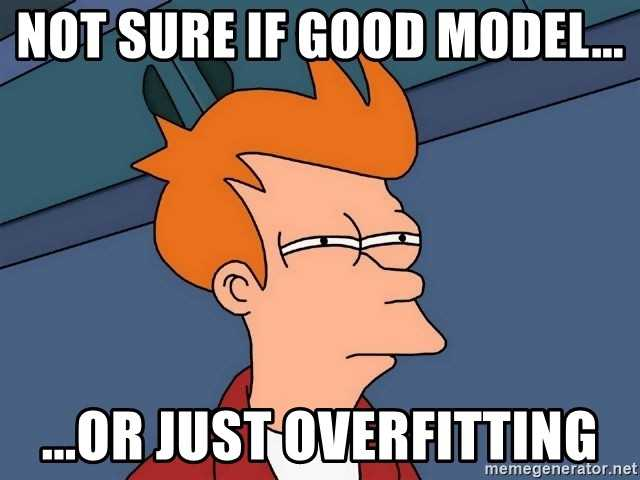

In [15]:
from IPython.display import Image, display

display(Image(filename="overfitunsurefry.webp"))

In [16]:
print("we are done, goodbye!")

we are done, goodbye!
